In [1]:
import os
import sys
import warnings
warnings.filterwarnings("ignore")
sys.path.append("/path/to/GeneSPOT")

from pathlib import Path
import pandas as pd
import seaborn as sns
import scanpy as sc
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from sklearn.metrics import adjusted_rand_score

matplotlib.rcParams['font.family'] = 'Aptos'
matplotlib.rcParams['pdf.fonttype'] = 42

In [2]:
%load_ext autoreload
%autoreload 2

from genespot.utils import seed_everything
from genespot.preprocess import preprocess_adata, filter_features, concat_features
from genespot.genespot import build_graph, topk_similar
from genespot.optimal_transports import cal_ot_distance
from genespot.graph_representation import node2vec
from genespot.visualization import create_cmap, legend_handles

random_state = 42
seed_everything(random_state)

In [3]:
RES_DIR = Path('/path/to/GeneSPOT/reproduce/fig3/res/paired')
OUTPUTS_DIR = Path('/path/to/GeneSPOT/reproduce/fig3/outputs/paired')
DOMAIN_IDENTIFICATION_DIR = Path('/path/to/GeneSPOT/reproduce/fig3/res/paired/domain_identification')

os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(OUTPUTS_DIR, exist_ok=True)

In [4]:
genespot = pd.read_csv(DOMAIN_IDENTIFICATION_DIR /'GeneSPOT/SpatialGlue_ari.csv', index_col=0)
genespot['method'] = 'GeneSPOT'
geary = pd.read_csv(DOMAIN_IDENTIFICATION_DIR / 'geary/SpatialGlue_ari.csv', index_col=0)
geary['method'] = 'Geary\' C'
moran = pd.read_csv(DOMAIN_IDENTIFICATION_DIR / 'moran/SpatialGlue_ari.csv', index_col=0)
moran['method'] = 'Moran\' I'
seurat = pd.read_csv(DOMAIN_IDENTIFICATION_DIR / 'seurat_v3/SpatialGlue_ari.csv', index_col=0)
seurat['method'] = 'Seurat_v3'
results = pd.concat([genespot, geary, moran, seurat], axis=0)

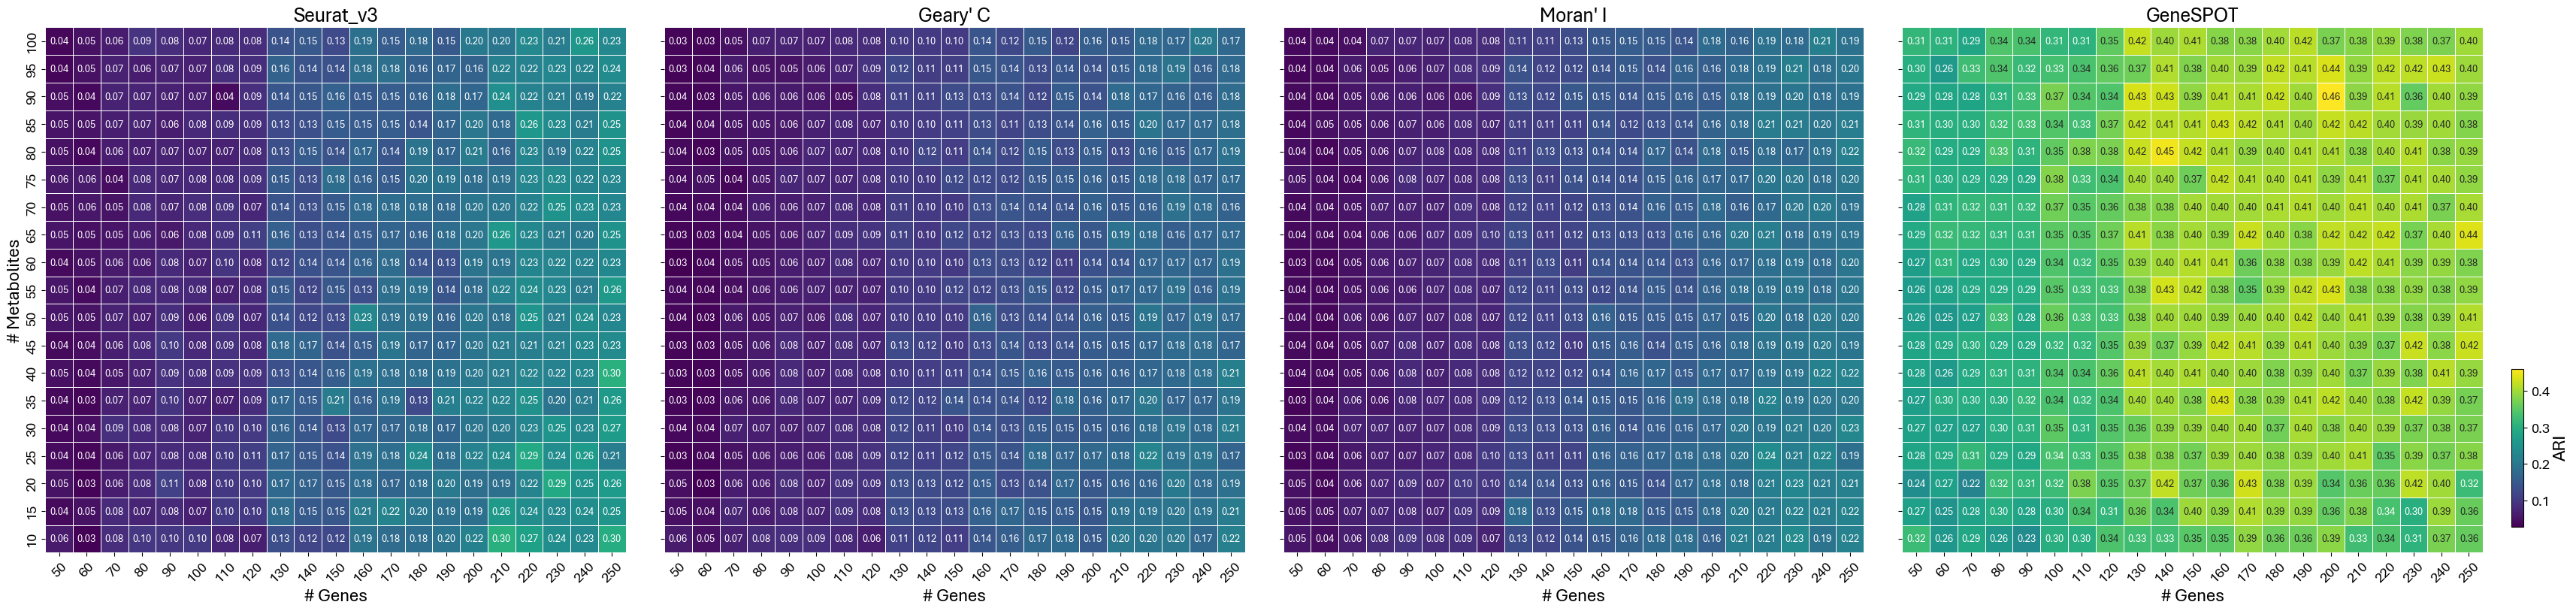

In [5]:
# Heatmap of ARI by n_gene (x) and n_msi (y) for each method
shown_n_gene = [50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 170, 180, 190, 200, 210, 220, 230, 240, 250]
shown_n_msi = [10, 15, 20, 25, 30, 35,  40,  45,  50,  55,  60,  65,  70,  75,  80,  85,  90,  95, 100]
sub_results = results[(results['n_gene'].isin(shown_n_gene)) & (results['n_msi'].isin(shown_n_msi))]
summary = (
    sub_results.groupby(["method", "n_msi", "n_gene"])['ARI']
    .mean()
    .reset_index()
)

cmap = 'viridis'
vmin, vmax = summary['ARI'].min(), summary['ARI'].max()
norm = plt.Normalize(vmin=vmin, vmax=vmax)

methods = ['Seurat_v3', 'Geary\' C', 'Moran\' I', 'GeneSPOT']

plotted_methods = []
for method in methods:
    method_data = summary[summary['method'] == method]
    if not method_data.empty:
        heatmap_data = (
            method_data.pivot(index='n_msi', columns='n_gene', values='ARI')
            .sort_index()
            .sort_index(axis=1)
        )
        if not heatmap_data.empty:
            plotted_methods.append(method)

if len(plotted_methods) > 0:
    fig, axes = plt.subplots(
        1, len(plotted_methods), figsize=(0.4 * len(shown_n_gene) * len(plotted_methods), 0.4 * len(shown_n_msi)), sharey=True
    )
    
    if len(plotted_methods) == 1:
        axes = [axes]
    
    for ax, method in zip(axes, plotted_methods):
        method_data = summary[summary['method'] == method]
        heatmap_data = (
            method_data.pivot(index='n_msi', columns='n_gene', values='ARI')
            .sort_index()
            .sort_index(axis=1)
        )
        sns.heatmap(
            heatmap_data,
            cmap=cmap,
            norm=norm,
            ax=ax,
            square=True, annot=True, fmt='.2f',
            linewidths=0.5,
            cbar=False,
        )
        ax.set_title(method, fontsize=20)
        ax.set_xlabel('# Genes', fontsize=18)
        ax.set_ylabel('# Metabolites' if ax is axes[0] else '', fontsize=18)
        ax.invert_yaxis()
    
    for ax in axes:
        ax.tick_params(axis='x', labelsize=14, rotation=45)
        ax.tick_params(axis='y', labelsize=14)
    
# single shared colorbar placed at bottom-right of the last axis
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cax = inset_axes(
    axes[-1],
    width="2%",
    height="30%",
    loc='lower left',
    bbox_to_anchor=(1.05, 0.05, 1, 1),
    bbox_transform=axes[-1].transAxes,
    borderpad=0,
)
cb = fig.colorbar(sm, cax=cax, label='ARI')
cb.ax.tick_params(labelsize=14)
cb.set_label('ARI', fontsize=18)

plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'fig3e_.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

In [6]:
import mudata as mu

raw_path = '/path/to/data/SMA_aligned/output'
b1_mdata = mu.read_h5mu(os.path.join(raw_path, 'B1.h5mu'))

annotations =        ['ACB',     'CP_intact', 'CP_lesioned', 'CTX',     'LSX',     'MSC',     'OT',      'VL',      'aco',     'cc']
annotations_colors = [
    '#9b9a71',  # ACB
    '#ee6055',  # CP_intact
    # '#da8376',  # CP_lesioned 
    '#516587',  # CP_lesioned 
    '#ba98c0',  # CTX
    '#bbd8b0',  # LSX 
    '#84584e',  # MSC
    '#9eb8b1',  # OT
    '#a9a9a9',  # VL
    '#e2d08a',  # aco
    '#cdd8e4',  # cc
]
b1_mdata.uns['Annotation_colors'] = annotations_colors
annotations_legends = legend_handles(annotations, annotations_colors)
annotation_color_map = dict(
    zip(annotations, annotations_colors)
)

In [7]:
genespot_cluster = pd.read_csv(DOMAIN_IDENTIFICATION_DIR / 'GeneSPOT' / 'SpatialGlue_g200_m100_r0.csv', index_col=0)
moran_cluster = pd.read_csv(DOMAIN_IDENTIFICATION_DIR / 'moran' / 'SpatialGlue_g200_m100_r0.csv', index_col=0)
geary_cluster = pd.read_csv(DOMAIN_IDENTIFICATION_DIR / 'geary' / 'SpatialGlue_g200_m100_r0.csv', index_col=0)
seurat_cluster = pd.read_csv(DOMAIN_IDENTIFICATION_DIR / 'seurat_v3' / 'SpatialGlue_g200_m100_r0.csv', index_col=0)

In [8]:
b1_mdata.obs['GeneSPOT'] = genespot_cluster['SpatialGlue'].astype('category')
b1_mdata.obs['Moran'] = moran_cluster['SpatialGlue'].astype('category')
b1_mdata.obs['Geary'] = geary_cluster['SpatialGlue'].astype('category')
b1_mdata.obs['Seurat'] = seurat_cluster['SpatialGlue'].astype('category')

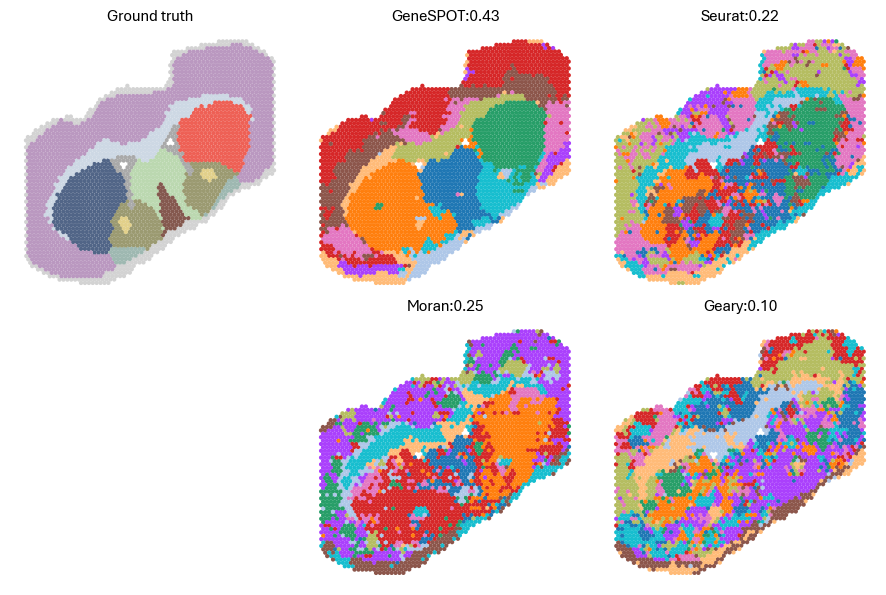

In [9]:
fig, axs = plt.subplots(2, 3, figsize=(9, 6))

gt = b1_mdata[b1_mdata.obs['Annotation'].notna()].copy()

methods = ['GeneSPOT', 'Seurat', 'Moran', 'Geary']

ax = axs[0, 0]
sc.pl.embedding(
    b1_mdata, 
    color='Annotation', basis='spatial',
    title='Ground truth',
    show=False, ax=ax,
    legend_loc=None,
    frameon=False,
)
ax.set_aspect(1)
ax.invert_xaxis()
ax.invert_yaxis()

positions = [(0, 1), (0, 2), (1, 1), (1, 2)]
for method, pos in zip(methods, positions):
    ax = axs[pos]
    ari = adjusted_rand_score(gt.obs['Annotation'], gt.obs[method])
    sc.pl.embedding(
        b1_mdata, 
        color=method, basis='spatial',
        title=f'{method}:{ari:.2f}',
        show=False, ax=ax,
        legend_loc=None,
        frameon=False,
    )
    ax.set_aspect(1)
    ax.invert_xaxis()
    ax.invert_yaxis()

# Set (1,0) empty
axs[1, 0].axis('off')

plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'fig3e.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()